# Part I

Here we plot and work with symbolic differentiation of multidimensional functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import sympy as sym

The following code demonstrates how to plot functions of two variables in three dimensions. The `meshgrid` command creates a two-dimensional grid. The function is then evluated at the grid points and plotted. I also included additional code for a colorbar that indicates the value of the function for each color in the plot.

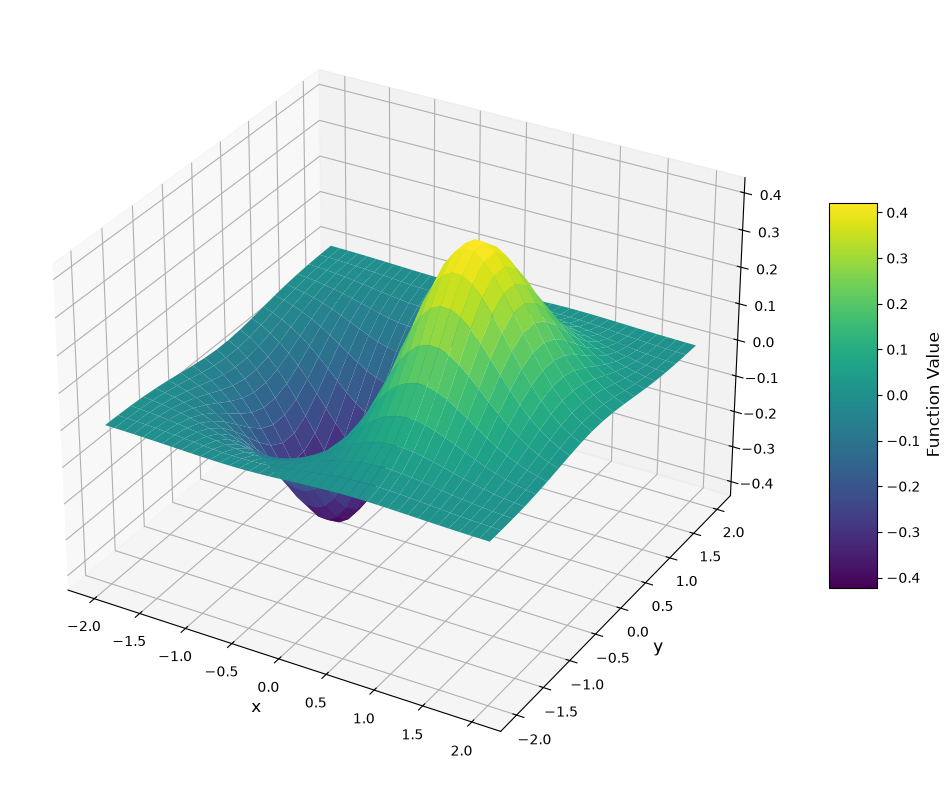

In [2]:
def my_function(x, y):
    return x*np.exp(-x**2 - y**2)


x = np.linspace(-2, 2, 40)
y = np.linspace(-2, 2, 20)

X, Y = np.meshgrid(x, y)
Z = my_function(X, Y)

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection='3d')

surface = ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)



cbar = fig.colorbar(surface, ax=ax, shrink=0.5, aspect=8)
cbar.set_label('Function Value', fontsize=12)
plt.tight_layout()


plt.show()

**Problem 1** By looking at the structure of `X` and `Y` that are returned from `meshgrid`, describe what this function does.  

In [3]:
# Inspect the coordinate arrays from the example above.
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("First two rows of X (first five columns):")
print(X[:2, :5])
print("First two rows of Y (first five columns):")
print(Y[:2, :5])

X shape: (20, 40)
Y shape: (20, 40)
First two rows of X (first five columns):
[[-2.         -1.8974359  -1.79487179 -1.69230769 -1.58974359]
 [-2.         -1.8974359  -1.79487179 -1.69230769 -1.58974359]]
First two rows of Y (first five columns):
[[-2.         -2.         -2.         -2.         -2.        ]
 [-1.78947368 -1.78947368 -1.78947368 -1.78947368 -1.78947368]]


`meshgrid` creates every combination of the supplied x and y coordinates.
Each row of `X` repeats the x coordinates, and each column of `Y` repeats
the y coordinates. Corresponding entries `X[i, j]` and `Y[i, j]` form one
grid point. Here both arrays have shape `(20, 40)`, giving 800 points.

**Problem 2** Plot the function `sin(xy)` with `x` and `y` each in the interval `[-3,3]`. Try to get a reasonably smooth plot. (You can increase the resolution in the `linspace` command if the plot looks too blocky.)

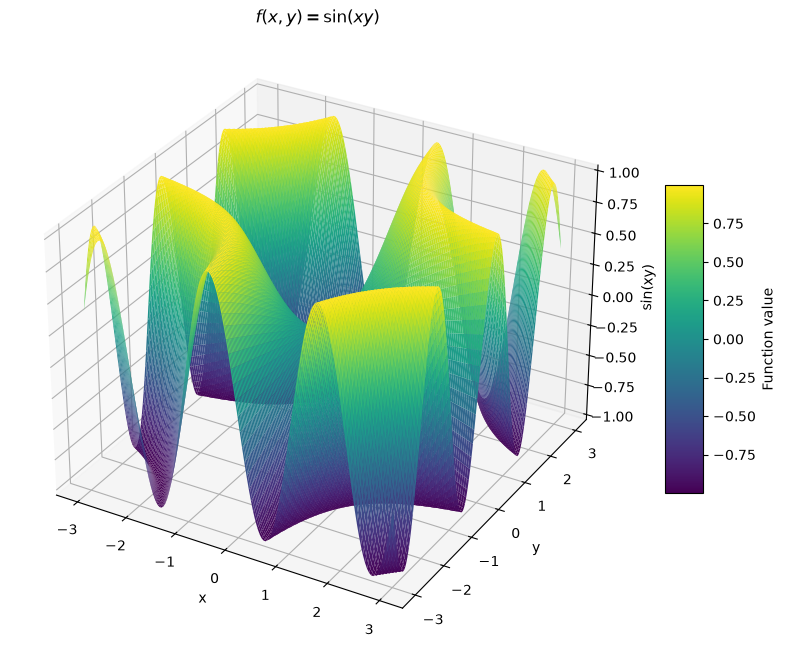

In [4]:
x_values = np.linspace(-3, 3, 150)
y_values = np.linspace(-3, 3, 150)
X, Y = np.meshgrid(x_values, y_values)
Z = np.sin(X * Y)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(X, Y, Z, cmap="viridis", rcount=150, ccount=150)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("sin(xy)")
ax.set_title(r"$f(x,y)=\sin(xy)$")
fig.colorbar(surface, ax=ax, shrink=0.5, aspect=8, label="Function value")
plt.show()

Recall your work with symbolic differentiation on the previous lab.  It works here too.

In [5]:
x, y, z = sym.symbols('x y z') #you only need to declare which symbols are variables once

In [6]:
my_expression = x**3 * y + y**3 + z

# Take partial derivatives

derivative1_x = sym.diff(my_expression, x)
print(derivative1_x)

derivative1_z = sym.diff(my_expression, z)
print(derivative1_z)

3*x**2*y
1


In [7]:
# evaluate at a point
point = {x: 1, y: 1, z: 1}
value = derivative1_x.subs(point)
print(value)

3


In [8]:
# take higher derivatives
derivative2_x = sym.diff(my_expression, x, 2)
print(derivative2_x)

6*x*y


**Problem 3** Symbolically take the two partial derivative of $ e^{xy}$ and evaluate at the point $(1/2, 3)$.  Use `sym.exp` for the exponential function.

In [9]:
exponential = sym.exp(x * y)
fx = sym.diff(exponential, x)
fy = sym.diff(exponential, y)
evaluation_point = {x: sym.Rational(1, 2), y: 3}

print("fx =", fx)
print("fy =", fy)
print("fx(1/2, 3) =", fx.subs(evaluation_point))
print("fy(1/2, 3) =", fy.subs(evaluation_point))
print("Decimal fx:", sym.N(fx.subs(evaluation_point)))
print("Decimal fy:", sym.N(fy.subs(evaluation_point)))

fx = y*exp(x*y)
fy = x*exp(x*y)
fx(1/2, 3) = 3*exp(3/2)
fy(1/2, 3) = exp(3/2)/2
Decimal fx: 13.4450672110142
Decimal fy: 2.24084453516903


**Problem 4** Symbolically find $f_{xx}$, $f_{xy}$, $f_{yx}$, and $f_{yy}$ for $f=\frac{4x^2}{y} + \frac{y^2}{2x}$

In [10]:
rational_function = 4*x**2/y + y**2/(2*x)
fxx = sym.diff(rational_function, x, 2)
fxy = sym.diff(rational_function, x, y)
fyx = sym.diff(rational_function, y, x)
fyy = sym.diff(rational_function, y, 2)

print("fxx =", fxx)
print("fxy =", fxy)
print("fyx =", fyx)
print("fyy =", fyy)
print("Mixed partials agree:", sym.simplify(fxy - fyx) == 0)

fxx = 8/y + y**2/x**3
fxy = -(8*x/y**2 + y/x**2)
fyx = -(8*x/y**2 + y/x**2)
fyy = 8*x**2/y**3 + 1/x
Mixed partials agree: True


## Part II

The following problems ask to you implement the gradient descent algorithm in one dimension and explore some of its properties.

### Goal: minimizing the function

Suppose our goal is to minimize a function and we don't know what the minimizer is. Suppose we initially start at point $\mathbf{x}_0 = \mathbf{a} = (1,1)$. Then using our understanding of the role of the gradient, one method is to *iteratively* move in the direction of the *negative* of the gradient, i.e. at each step $t$, if our current position is $\mathbf{x}_t$ then we do the update

$$\mathbf{x}_{t+1} = \mathbf{x}_t - \eta \nabla f(\mathbf{x}_t)$$

where $\eta$ is the "small" move in the direction of the negative of the gradient and is often called the *learning* rate.


**Problem 5** Write a function with two arguments, a learning rate parameter and an initial guess. The function should perform 10 iterations of gradient descent with `f(x) = x^2/2` and the given initial guess, then return the resulting value. Print the result of the function applied with initial value 10 and the following learning rates: 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 3. The gradient descent calculations/iterations should be written out explicitly; don't just call a library function.



In [11]:
def gd(learning_rate, initial_guess):
    current_x = float(initial_guess)
    for _ in range(10):
        derivative = current_x  # f'(x) = x for f(x) = x**2 / 2
        current_x = current_x - learning_rate * derivative
    return current_x


learning_rates = [0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 3]
for rate in learning_rates:
    result = gd(rate, 10)
    print(f"Learning rate {rate}: x = {result}, f(x) = {result**2 / 2}")

Learning rate 0.25: x = 0.5631351470947266, f(x) = 0.15856059694669966
Learning rate 0.5: x = 0.009765625, f(x) = 4.76837158203125e-05
Learning rate 0.75: x = 9.5367431640625e-06, f(x) = 4.547473508864641e-11
Learning rate 1: x = 0.0, f(x) = 0.0
Learning rate 1.25: x = 9.5367431640625e-06, f(x) = 4.547473508864641e-11
Learning rate 1.5: x = 0.009765625, f(x) = 4.76837158203125e-05
Learning rate 1.75: x = 0.5631351470947266, f(x) = 0.15856059694669966
Learning rate 2: x = 10.0, f(x) = 50.0
Learning rate 3: x = 10240.0, f(x) = 52428800.0


**Problem 6** Which learning rate gives the most accurate value for the minimum? Which gives the last accurate value? (You may wish to look at the discussion of the rate of convergence for gradient descent for this function in the notes. The answers can also be deduced from the analysis there.)

The most accurate learning rate is **1**, which reaches the minimizer
$x=0$ in one step. The least accurate tested rate is **3**, which gives
$x=10240$ after ten steps.

Since $f'(x)=x$, the update is $x_{t+1}=(1-\eta)x_t$, so
$x_{10}=10(1-\eta)^{10}$. Convergence requires $|1-\eta|<1$, or
$0<\eta<2$. Rates between 1 and 2 alternate sides while converging;
rate 2 oscillates between 10 and -10, and rate 3 diverges.

**Problem 7** Consider the function `f(x)= x^4 - 4x^2 + x`. Use gradient descent to find the value of `x` that achieves the global minimum, and the value of `f(x)` at that point. Print both values. To get full points, you must get the first three digits of each number right. (For example, if the true minimizer is 3.1415..., then your answer must begin 3.14... to get full credit.)

The gradient descent calculations/iterations should be written out explicitly; don't just call a library function.

**Hint 1.** This function is not convex, so it is possible for gradient descent to converge to the wrong local minimum.

**Hint 2.** Choosing a good learning rate is crucial here. If it is too large, it won't converge. You will need values a bit smaller than the previous example. Try a range of values. If you try many small learning rate parameters and they all give the same result, this should increase your confidence in your answer. Also, try increasing the number of iterations.

In [12]:
def quartic(x):
    return x**4 - 4*x**2 + x


def quartic_gd(learning_rate, initial_guess, iterations=1000):
    current_x = float(initial_guess)
    for _ in range(iterations):
        derivative = 4*current_x**3 - 8*current_x + 1
        current_x = current_x - learning_rate * derivative
    return current_x


# Compare both basins using several starting points and learning rates.
quartic_results = []
for rate in [0.01, 0.025, 0.05]:
    for start in [-2, 0, 2]:
        final_x = quartic_gd(rate, start)
        final_value = quartic(final_x)
        quartic_results.append((final_x, final_value))
        print(f"rate={rate}, start={start}: x={final_x:.9f}, f(x)={final_value:.9f}")

best_x, best_value = min(quartic_results, key=lambda result: result[1])
print(f"\nGlobal minimizing x: {best_x:.9f}")
print(f"Global minimum f(x): {best_value:.9f}")

rate=0.01, start=-2: x=-1.472997601, f(x)=-5.444192067
rate=0.01, start=0: x=-1.472997601, f(x)=-5.444192067
rate=0.01, start=2: x=1.346997409, f(x)=-2.618555981
rate=0.025, start=-2: x=-1.472997601, f(x)=-5.444192067
rate=0.025, start=0: x=-1.472997601, f(x)=-5.444192067
rate=0.025, start=2: x=1.346997409, f(x)=-2.618555981
rate=0.05, start=-2: x=-1.472997601, f(x)=-5.444192067
rate=0.05, start=0: x=-1.472997601, f(x)=-5.444192067
rate=0.05, start=2: x=1.346997409, f(x)=-2.618555981

Global minimizing x: -1.472997601
Global minimum f(x): -5.444192067


Gradient descent gives $x\approx-1.472997601$ and
$f(x)\approx-5.444192067$. The positive local minimum has the higher
value $f(x)\approx-2.618555981$. The quartic tends to positive infinity
at both ends, and its derivative has two local minima separated by a
local maximum; comparing the two minima identifies the global minimum.

**Problem 8** Let's move to 2D.  Add the lines of code for the gradient and the implimentation of gradient descent.

In [13]:
# Function to minimize
def function(x, y):
    return x**2 + y**2


# Gradient: [df/dx, df/dy]
def gradient(x, y):
    return np.array([2*x, 2*y])


def gradient_descent(start_point, learning_rate, iterations):
    current_point = np.array(start_point, dtype=float)
    trajectory = [current_point.tolist()]

    for _ in range(iterations):
        grad = gradient(*current_point)
        current_point = current_point - learning_rate * grad
        trajectory.append(current_point.tolist())

    return np.array(trajectory)

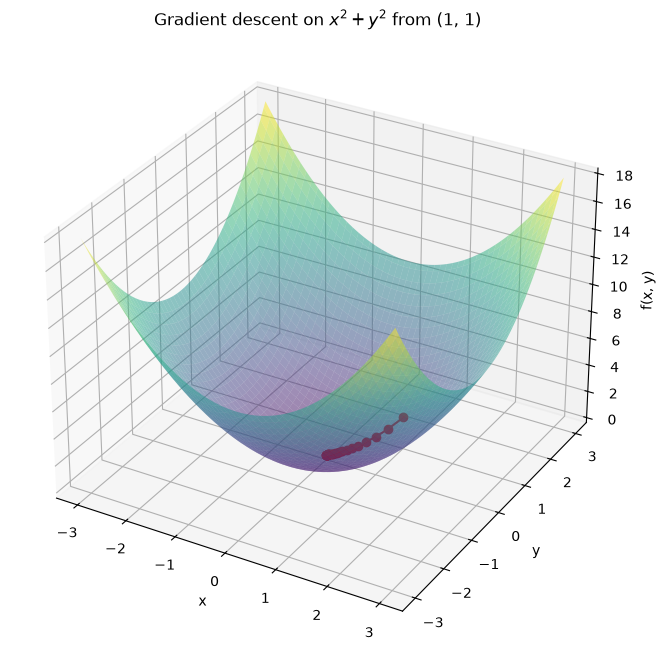

Final point: [0.00123794 0.00123794]
Final function value: 3.0649910817317793e-06


In [14]:
start_point = [1, 1]
learning_rate = 0.1
iterations_descent = 30

descent_trajectory = gradient_descent(start_point, learning_rate, iterations_descent)

x_values = np.linspace(-3, 3, 100)
y_values = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_values, y_values)
Z = function(X, Y)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.5)

path_x = descent_trajectory[:, 0]
path_y = descent_trajectory[:, 1]
ax.plot(path_x, path_y, function(path_x, path_y), marker="o", color="red")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
ax.set_title(r"Gradient descent on $x^2+y^2$ from (1, 1)")
plt.show()

print("Final point:", descent_trajectory[-1])
print("Final function value:", function(*descent_trajectory[-1]))

**Problem 9**
Modify the above code to understand the behavior now for the function

$$f(x,y) =.01*( x^6 + y^6 + 3)$$

You might need to modify the learning rates so you can actually see the iterations moving.

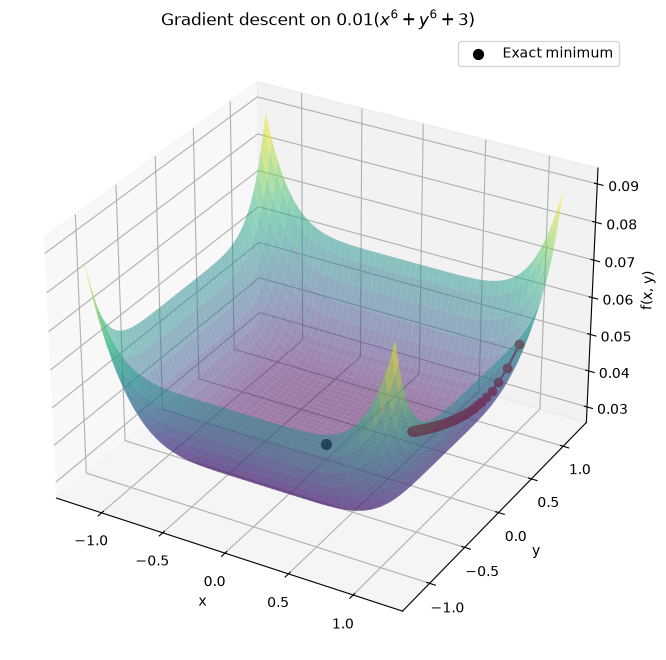

Final point after 100 iterations: [0.44500272 0.44500272]
Final function value: 0.030155312343168778
Exact minimum: f(0, 0) = 0.03
rate=0.1: point=[0.73542771 0.73542771], f=0.033164244
rate=1.0: point=[0.44500272 0.44500272], f=0.030155312
rate=2.0: point=[0.37559956 0.37559956], f=0.030056154


In [15]:
# The gradient is [0.06*x**5, 0.06*y**5].
def function(x, y):
    return 0.01 * (x**6 + y**6 + 3)


def gradient(x, y):
    return np.array([0.06*x**5, 0.06*y**5])


# Reuse gradient_descent from Problem 8 with the new gradient.
start_point = [1, 1]
learning_rate = 1.0
iterations_descent = 100
sixth_power_trajectory = gradient_descent(start_point, learning_rate, iterations_descent)

x_values = np.linspace(-1.2, 1.2, 100)
y_values = np.linspace(-1.2, 1.2, 100)
X, Y = np.meshgrid(x_values, y_values)
Z = function(X, Y)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.5)
path_x = sixth_power_trajectory[:, 0]
path_y = sixth_power_trajectory[:, 1]
ax.plot(path_x, path_y, function(path_x, path_y), marker="o", color="red")
ax.scatter([0], [0], [0.03], color="black", s=50, label="Exact minimum")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
ax.set_title(r"Gradient descent on $0.01(x^6+y^6+3)$")
ax.legend()
plt.show()

print("Final point after 100 iterations:", sixth_power_trajectory[-1])
print("Final function value:", function(*sixth_power_trajectory[-1]))
print("Exact minimum: f(0, 0) = 0.03")

# Compare learning rates from the same starting point.
for rate in [0.1, 1.0, 2.0]:
    trajectory = gradient_descent(start_point, rate, iterations_descent)
    print(f"rate={rate}: point={trajectory[-1]}, f={function(*trajectory[-1]):.9f}")

The exact minimum is at $(0,0)$ with value $0.03$, since sixth powers
are nonnegative. The gradient becomes very small near zero, so the
iterations slow down substantially. A learning rate of 1 works from
$(1,1)$, but more distant starting points may require a smaller rate.